# Domain: Human Resources / People Analytics

## Context of Dataset

**INX Future Inc.** is a 15+ year data analytics & automation solutions provider, consistently rated a
top-20 employer. Recently its **employee performance indexes have declined**, escalations on service
delivery have risen, and client satisfaction has dropped 8 percentage points. The CEO wants the root
causes identified — and a model that can flag genuinely non-performing employees — **without** a
blanket, morale-damaging crackdown on staff or damage to INX's "best employer" reputation.

This notebook builds a model to **predict `PerformanceRating`** from employee attributes, and — just as
importantly for this brief — surfaces **which factors drive performance**, so any action taken is
targeted and evidence-based rather than blanket.

Attribute information (28 columns, 1200 employees):
- `EmpNumber` — unique employee ID (not predictive — dropped before modelling)
- `Age`, `Gender`, `EducationBackground`, `MaritalStatus` — demographics
- `EmpDepartment`, `EmpJobRole`, `BusinessTravelFrequency`, `DistanceFromHome` — role/location
- `EmpEducationLevel` (1 'Below College' – 5 'Doctor')
- `EmpEnvironmentSatisfaction`, `EmpJobInvolvement`, `EmpJobSatisfaction`,
  `EmpRelationshipSatisfaction`, `EmpWorkLifeBalance` (all 1 'Low' – 4 'Very High')
- `EmpHourlyRate`, `EmpJobLevel`, `EmpLastSalaryHikePercent`, `NumCompaniesWorked`, `OverTime`
- `TotalWorkExperienceInYears`, `TrainingTimesLastYear`, `ExperienceYearsAtThisCompany`,
  `ExperienceYearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager`
- `Attrition` — whether the employee has since left (`Yes`/`No`)

Target:
- `PerformanceRating` — **1** 'Low' (not present in this data), **2** 'Good', **3** 'Excellent',
  **4** 'Outstanding'. This makes it a **3-class classification** problem (the data only contains
  ratings 2, 3, and 4) — different from binary classification, and the modelling/metric choices below are adapted accordingly.

## Task 1: Data Analysis Report
## Step 1: Loading the Dataset

In [38]:
# Importing required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, ConfusionMatrixDisplay)
import pickle
import random

#### A note on the source file

The original file supplied, `INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1_8.xls`, is a
**legacy `.xls`** file, which needs the separate `xlrd` package to read directly and doesn't open with
the more common `openpyxl` engine. It's been converted once to `employee_performance.xlsx` (same data,
both sheets preserved) so this notebook runs with just `pandas` + `openpyxl` and no extra installs.

In [40]:
data_path = '/Users/anmolgupta/Desktop/Datamites Internship/IABAC Project/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls'

xls = pd.ExcelFile(data_path)
print('Sheets found:', xls.sheet_names)

Sheets found: ['INX_Future_Inc_Employee_Perform', 'Data Definitions']


In [41]:
# The data dictionary sheet — decodes what the 1-4 / 1-5 numeric codes mean (e.g. PerformanceRating: 2='Good', 3='Excellent', 4='Outstanding')

data_definitions = pd.read_excel(xls, sheet_name='Data Definitions')
data_definitions.head(30)

,Unnamed: 0,Unnamed: 1
0,NaN,NaN
1,EmpEducationLevel,1 'Below College'
2,NaN,2 'College'
3,NaN,3 'Bachelor'
4,NaN,4 'Master'
5,NaN,5 'Doctor'
6,NaN,NaN
7,EmpEnvironmentSatisfaction,1 'Low'
8,NaN,2 'Medium'
9,NaN,3 'High'


In [42]:
original_data = pd.read_excel(xls, sheet_name='INX_Future_Inc_Employee_Perform')
print(original_data.shape)
original_data.head()

(1200, 28)


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [43]:
df = original_data.copy()  # working copy so the original loaded data stays untouched
df.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


## Step 2: Initial Basic Checks

In [45]:
df.shape

(1200, 28)

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

In [47]:
# EmpNumber is just a row identifier, not a predictive feature — drop it now so it
# never accidentally leaks into scaling/encoding/model steps later.

df = df.drop(columns=['EmpNumber'])
df.head()

,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,4,...,4,10,2,2,10,7,0,8,No,3
1,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,4,...,4,20,2,3,7,7,1,7,No,3
2,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,4,...,3,20,2,3,18,13,1,12,No,4
3,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,2,...,2,23,2,2,21,6,12,6,No,3
4,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,1,...,4,10,1,3,2,2,2,2,No,3


In [48]:
df.isnull().sum()   # check for missing values

Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

In [49]:
df.duplicated().sum()   # check for duplicate rows

0

In [50]:
df.describe()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
count,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,2.89250,2.715833,65.981667,2.731667,2.067500,2.732500,2.665000,15.222500,2.725000,11.330000,2.785833,2.744167,7.077500,4.291667,2.194167,4.105000,2.948333
std,9.087289,8.176636,1.04412,1.090599,20.211302,0.707164,1.107836,1.100888,2.469384,3.625918,1.075642,7.797228,1.263446,0.699374,6.236899,3.613744,3.221560,3.541576,0.518866
min,18.000000,1.000000,1.00000,1.000000,30.000000,1.000000,1.000000,1.000000,0.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,30.000000,2.000000,2.00000,2.000000,48.000000,2.000000,1.000000,2.000000,1.000000,12.000000,2.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,3.000000
50%,36.000000,7.000000,3.00000,3.000000,66.000000,3.000000,2.000000,3.000000,2.000000,14.000000,3.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,3.000000
75%,43.000000,14.000000,4.00000,4.000000,83.000000,3.000000,3.000000,4.000000,4.000000,18.000000,4.000000,15.000000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,29.000000,5.00000,4.000000,100.000000,4.000000,5.000000,4.000000,9.000000,25.000000,4.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


In [51]:
df['PerformanceRating'].value_counts().sort_index()

PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64

In [52]:
rating_labels = {2: 'Good', 3: 'Excellent', 4: 'Outstanding'}   # from the Data Definitions sheet

df['PerformanceRating'].map(rating_labels).value_counts(normalize=True).mul(100).round(1)

PerformanceRating
Excellent      72.8
Good           16.2
Outstanding    11.0
Name: proportion, dtype: float64

#### Note:

There are **no missing values and no duplicate rows**. The target is **imbalanced**: about 73% of
employees are rated "Excellent" (3), with "Good" (2, ~16%) and "Outstanding" (4, ~11%) both notably
smaller — every model below needs to be judged on more than plain accuracy, or it could just predict
"Excellent" for everyone and still look decent. This is handled with **macro-averaged metrics** (which
weight all 3 classes equally, not by how common they are) plus SMOTE on the training data.

## Step 3: EDA — Univariate & Bivariate Analysis

### 1. Univariate Analysis

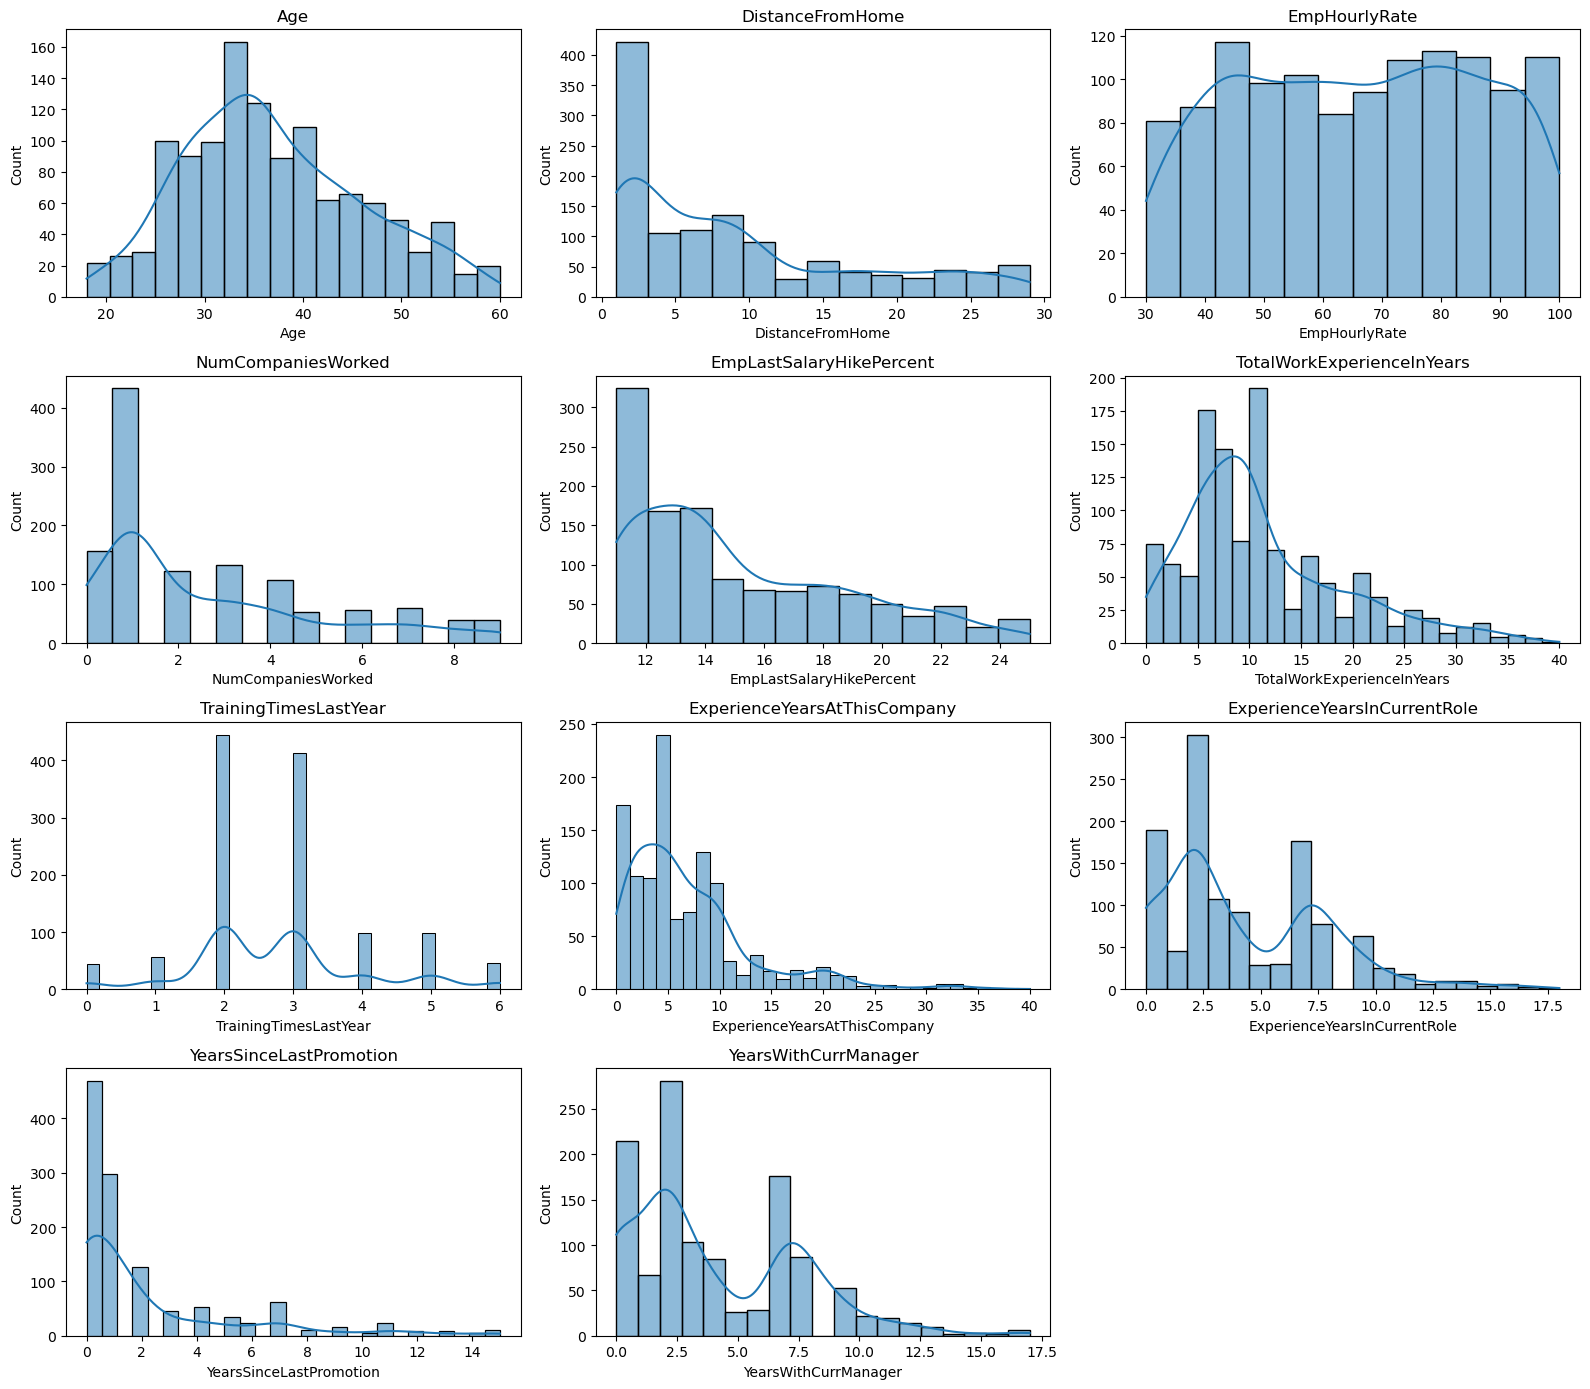

In [56]:
continuous_cols = ['Age', 'DistanceFromHome', 'EmpHourlyRate', 'NumCompaniesWorked',
                    'EmpLastSalaryHikePercent', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear',
                    'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole',
                    'YearsSinceLastPromotion', 'YearsWithCurrManager']

plt.figure(figsize=(16,14), facecolor='white')
for i, col in enumerate(continuous_cols):
    plt.subplot(4, 3, i+1)
    sns.histplot(x=df[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Histograms:

- `Age`, `EmpHourlyRate` are roughly evenly spread.
- `NumCompaniesWorked`, `TotalWorkExperienceInYears`, `ExperienceYearsAtThisCompany`,
  `YearsSinceLastPromotion` are all **right-skewed** — most employees are early/mid-career or recently
  promoted, with a long tail of more tenured staff.
- The satisfaction/involvement scores (`EmpEnvironmentSatisfaction`, `EmpJobInvolvement`, etc.) are
  already ordinal 1–4 codes, not continuous measurements — handled as pass-through features later
  rather than being standard-scaled.

#### Categorical Column Distributions

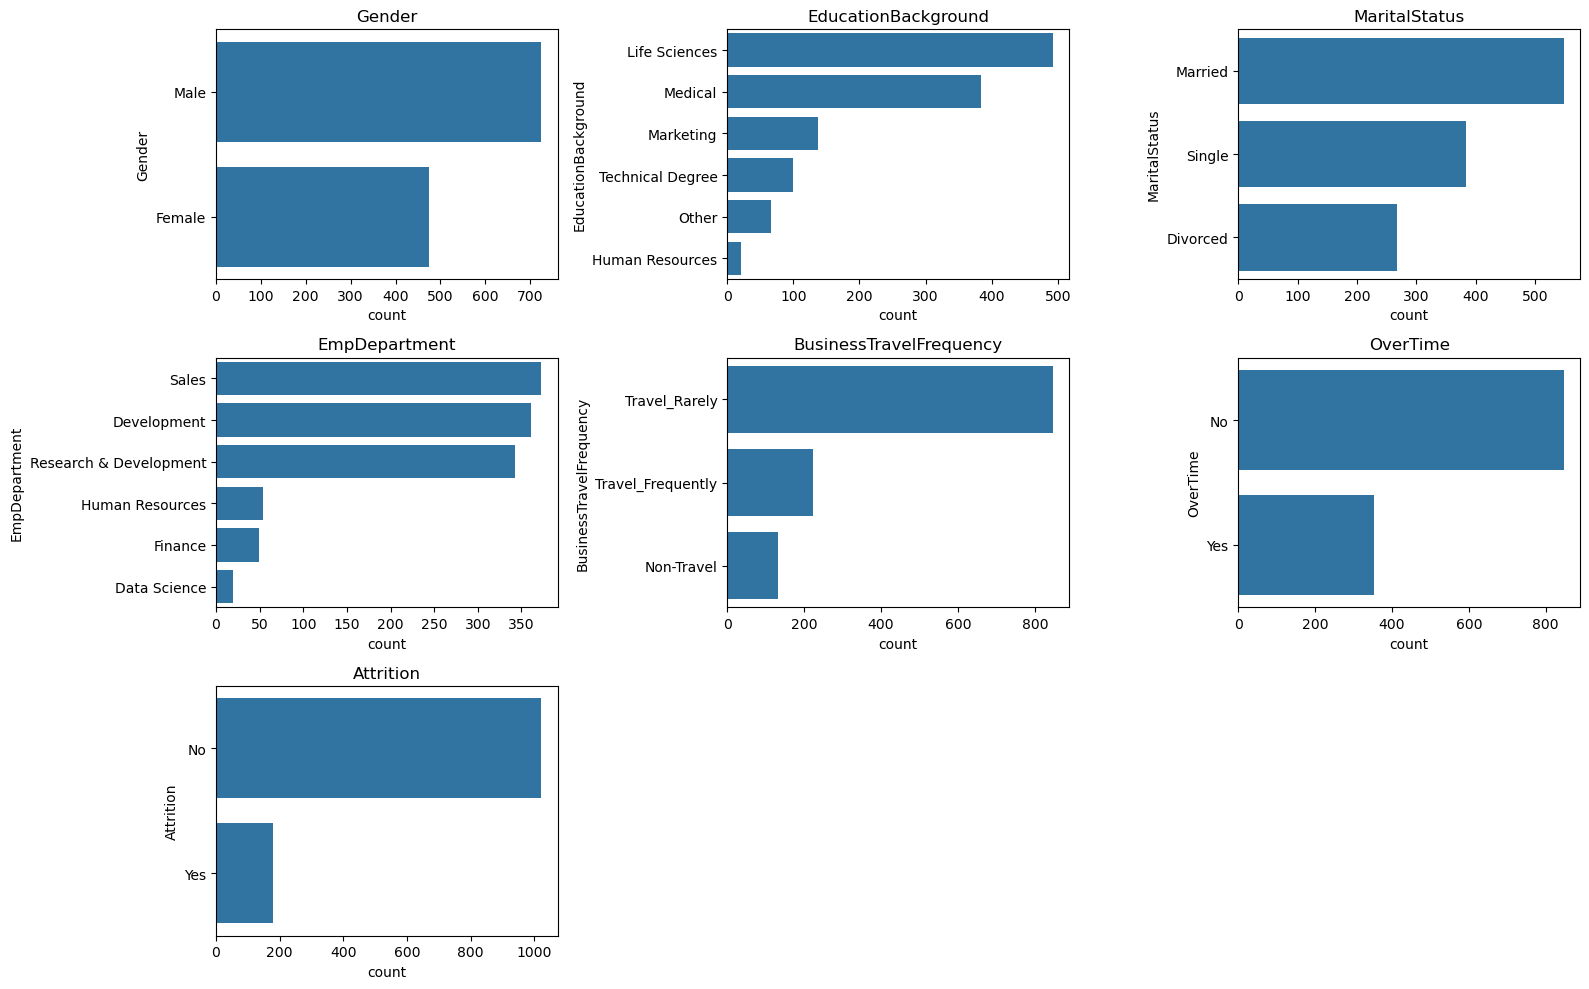

In [59]:
cat_col = ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment',
           'BusinessTravelFrequency', 'OverTime', 'Attrition']

plt.figure(figsize=(16,10), facecolor='white')
for i, col in enumerate(cat_col):
    plt.subplot(3, 3, i+1)
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order)
    plt.title(col)
plt.tight_layout()
plt.show()

### 2. Bivariate / Multivariate Analysis

#### Plotting Boxplots (outlier check on continuous predictors)

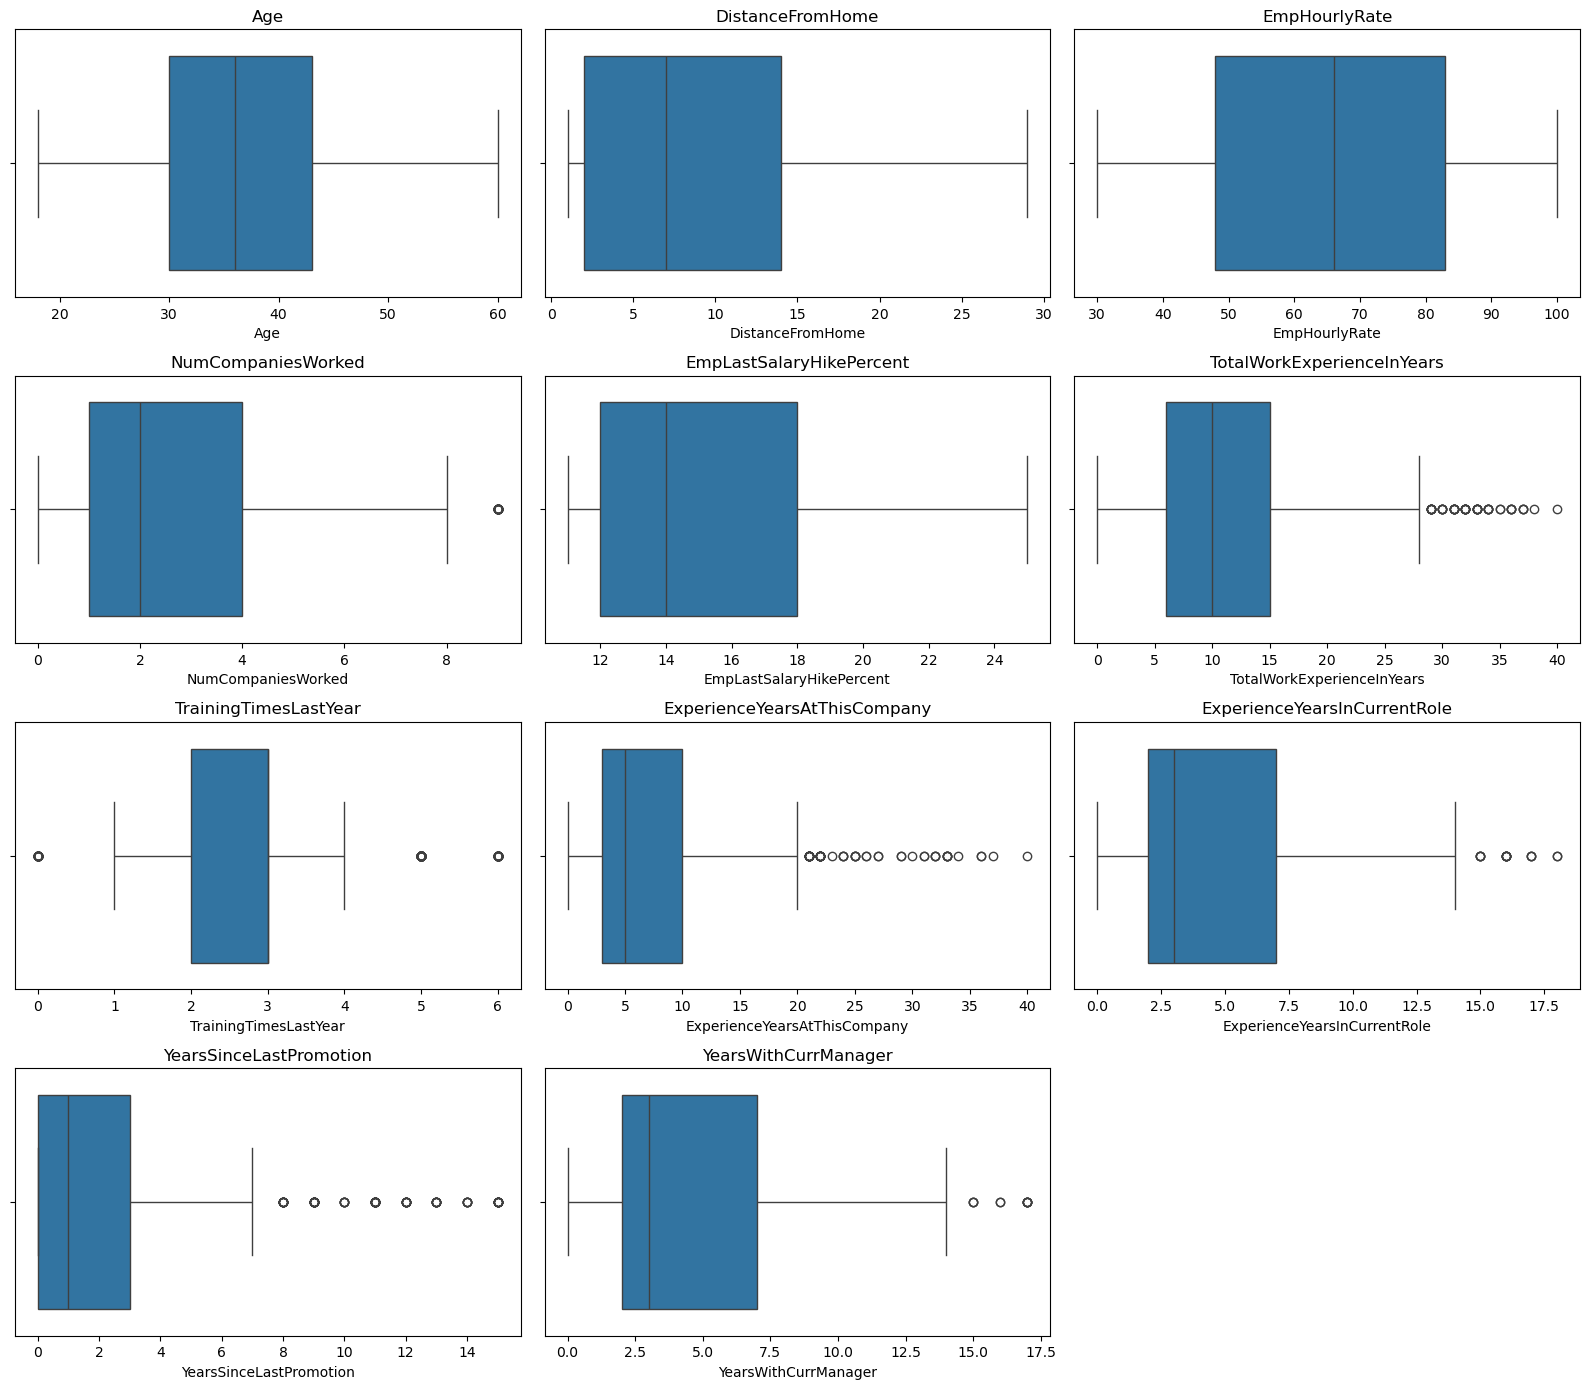

In [62]:
plt.figure(figsize=(16,14), facecolor='white')
for i, col in enumerate(continuous_cols):
    plt.subplot(4, 3, i+1)
    sns.boxplot(x=df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Boxplots:

`NumCompaniesWorked`, `TotalWorkExperienceInYears`, `ExperienceYearsAtThisCompany`,
`ExperienceYearsInCurrentRole`, `YearsSinceLastPromotion`, and `YearsWithCurrManager` all show a
meaningful number of high-end outliers — consistent with their right-skew above. Since these are
**predictor** columns (not the target), they're capped with IQR winsorizing in the Preprocessing step,
same treatment as the predictor-outlier handling in the earlier notebooks.

#### Key Drivers vs. PerformanceRating

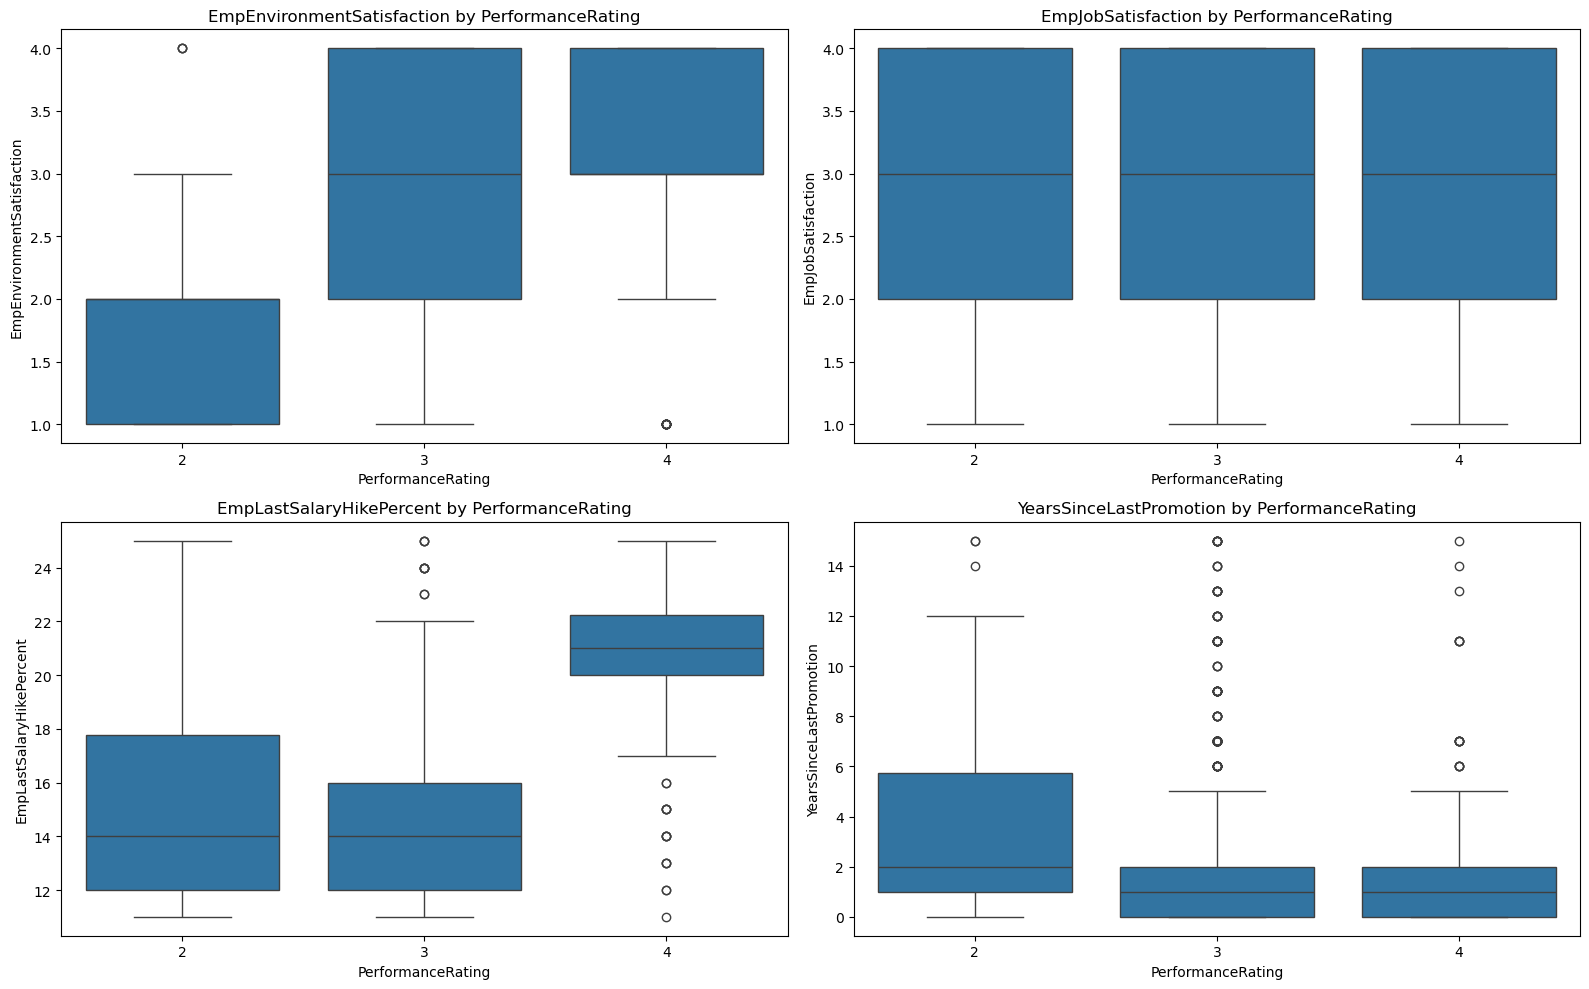

In [65]:
driver_cols = ['EmpEnvironmentSatisfaction', 'EmpJobSatisfaction', 'EmpLastSalaryHikePercent',
               'YearsSinceLastPromotion']

plt.figure(figsize=(16,10))
for i, col in enumerate(driver_cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(x='PerformanceRating', y=col, data=df)
    plt.title(f'{col} by PerformanceRating')
plt.tight_layout()
plt.show()

In [66]:
df.groupby('PerformanceRating')[driver_cols].mean().round(2)

,EmpEnvironmentSatisfaction,EmpJobSatisfaction,EmpLastSalaryHikePercent,YearsSinceLastPromotion
PerformanceRating,,,,
2,1.58,2.75,15.07,3.70
3,2.91,2.72,14.43,1.91
4,3.08,2.77,20.70,1.86


**Finding:** `EmpEnvironmentSatisfaction` is sharply lower for rating 2 ("Good") than for ratings 3–4 —
the clearest single split in the data. `EmpLastSalaryHikePercent` stands out for rating 4
("Outstanding"), which is expected (top performers get bigger raises) but is worth flagging as a
possible **feedback loop** rather than a pure cause: a model trained on this could partly be learning
"who already got a big raise" rather than "who is about to perform well". `YearsSinceLastPromotion` is
notably higher among rating-2 employees — a stalled promotion track lining up with lower performance.
These patterns are followed up properly in the **Key Driver Analysis** section after modelling, using
the trained model's feature importances rather than eyeballed averages alone.

In [68]:
pd.crosstab(df['OverTime'], df['PerformanceRating'], normalize='index').round(3)

PerformanceRating,2,3,4
OverTime,,,
No,0.183,0.702,0.115
Yes,0.110,0.790,0.099


In [69]:
df.groupby('EmpDepartment')['PerformanceRating'].mean().sort_values().round(2)

EmpDepartment
Finance                   2.78
Sales                     2.86
Research & Development    2.92
Human Resources           2.93
Data Science              3.05
Development               3.09
Name: PerformanceRating, dtype: float64

#### Correlation Heatmap

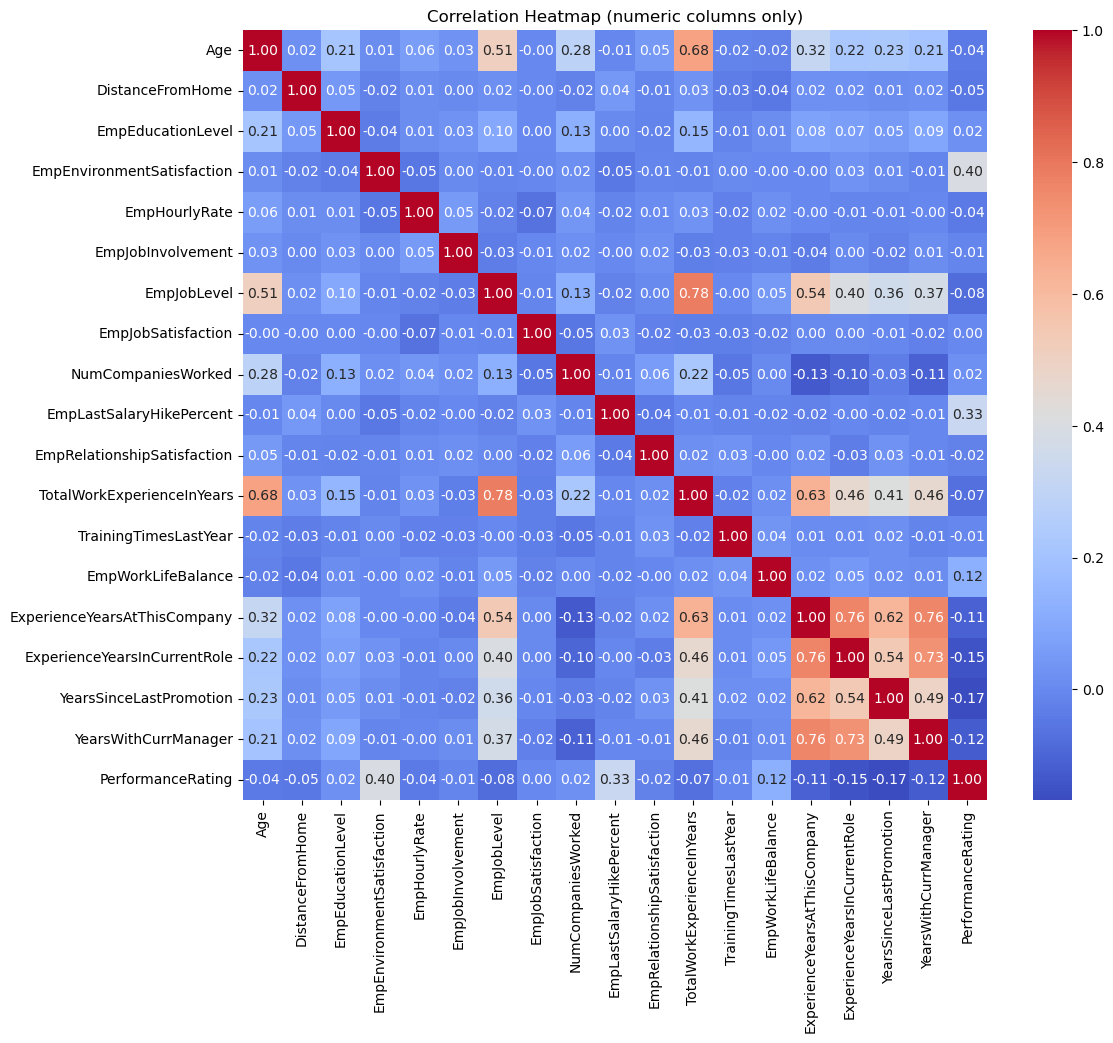

In [71]:
plt.figure(figsize=(12,10))
sns.heatmap(df.select_dtypes(include=['int64','float64']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (numeric columns only)')
plt.show()

**Finding:** no pair of predictor columns is strongly collinear (nothing near 0.8+), so there's no
need to drop features purely on multicollinearity grounds. The moderate correlation cluster among
`ExperienceYearsAtThisCompany`, `ExperienceYearsInCurrentRole`, and `YearsWithCurrManager` is expected —
they all track tenure — but not strong enough to justify dropping any of them outright.

## Step 4: Data Preprocessing

#### Imputing Null Values

There are no null values in this dataset (confirmed above). The code below is kept as a defensive,
reusable safeguard for future data refreshes: median imputation for the continuous columns, mode for
the categorical ones.

In [75]:
categorical_like_cols = ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole',
                          'BusinessTravelFrequency', 'OverTime', 'Attrition', 'EmpEducationLevel',
                          'EmpEnvironmentSatisfaction', 'EmpJobInvolvement', 'EmpJobLevel',
                          'EmpJobSatisfaction', 'EmpRelationshipSatisfaction', 'EmpWorkLifeBalance']

for c in continuous_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())

for c in categorical_like_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum().sum()

0

#### Dropping Duplicate Rows

In [77]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)   # no-op here since none exist, kept for pipeline completeness
print('Shape after de-duplication:', df.shape)

Duplicate rows: 0
Shape after de-duplication: (1200, 27)


#### Capping Outliers with the IQR Method

Applied to the right-skewed continuous predictor columns flagged in the EDA boxplots. Unlike the
insurance notebook's *target* (which was deliberately left uncapped), these are all **predictor**
columns here, so capping the extreme values is appropriate and doesn't discard the thing the model is
trying to predict.

In [79]:
winsor_cols = ['NumCompaniesWorked', 'TotalWorkExperienceInYears', 'ExperienceYearsAtThisCompany',
               'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

for col in winsor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

df[winsor_cols].describe()

,NumCompaniesWorked,TotalWorkExperienceInYears,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.00000
mean,2.648750,11.158750,6.823333,4.269167,1.925833,4.08875
std,2.428923,7.340549,5.412627,3.542434,2.473277,3.48837
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,1.000000,6.000000,3.000000,2.000000,0.000000,2.00000
50%,2.000000,10.000000,5.000000,3.000000,1.000000,3.00000
75%,4.000000,15.000000,10.000000,7.000000,3.000000,7.00000
max,8.500000,28.500000,20.500000,14.500000,7.500000,14.50000


In [80]:
# Saving the cleaned dataset (mirrors the checkpoint pattern used in the earlier notebooks)

with open('Employee_processed_file.pkl', 'wb') as f:
    pickle.dump(df, f)

## Step 5: Feature Engineering

#### Defining Column Groups for the Preprocessing Pipeline

- The **nominal categorical** columns (no inherent order) → One-Hot Encode.
- The genuinely **continuous** measurements → Standard Scale.
- The columns that are **already ordinal codes** (`EmpEducationLevel`, the four satisfaction/involvement
  scores, `EmpJobLevel`) → pass through unscaled; scaling a 1–4/1–5 ordinal code doesn't help a tree
  model and isn't meaningful the way scaling a raw continuous measurement is.

In [83]:
nominal_cat_cols = ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole',
                     'BusinessTravelFrequency', 'OverTime', 'Attrition']

ordinal_passthrough_cols = ['EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpJobInvolvement',
                             'EmpJobLevel', 'EmpJobSatisfaction', 'EmpRelationshipSatisfaction',
                             'EmpWorkLifeBalance']

scale_cols = continuous_cols   # defined in the EDA step: Age, DistanceFromHome, EmpHourlyRate, etc.

#### Building the Preprocessing Pipeline

In [85]:
preprocessor = ColumnTransformer([
    ('OHE', OneHotEncoder(handle_unknown='ignore'), nominal_cat_cols),
    ('SS', StandardScaler(), scale_cols),
    ('Do_Nothing', 'passthrough', ordinal_passthrough_cols)
])

preprocessor

ColumnTransformer(transformers=[('OHE', OneHotEncoder(handle_unknown='ignore'),
                                 ['Gender', 'EducationBackground',
                                  'MaritalStatus', 'EmpDepartment',
                                  'EmpJobRole', 'BusinessTravelFrequency',
                                  'OverTime', 'Attrition']),
                                ('SS', StandardScaler(),
                                 ['Age', 'DistanceFromHome', 'EmpHourlyRate',
                                  'NumCompaniesWorked',
                                  'EmpLastSalaryHikePercent',
                                  'TotalWorkExperienceInYears',
                                  'TrainingTimesLastYear',
                                  'ExperienceYearsAtThisCompany',
                                  'ExperienceYearsInCurrentRole',
                                  'YearsSinceLastPromotion',
                                  'YearsWithCurrManager']),
                                ('Do_Nothing', 'passthrough',
                                 ['EmpEducationLevel',
                                  'EmpEnvironmentSatisfaction',
                                  'EmpJobInvolvement', 'EmpJobLevel',
                                  'EmpJobSatisfaction',
                                  'EmpRelationshipSatisfaction',
                                  'EmpWorkLifeBalance'])])

In [86]:
# Saving the preprocessor for re-use / deployment

with open('Employee_CT.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

#### Encoding the Target

`PerformanceRating` is stored as `{2, 3, 4}`. Several classifiers (XGBoost in particular) require
class labels to start at 0 and run consecutively, so it's re-mapped to `{0, 1, 2}` here, with the
mapping kept so every prediction can be converted straight back to `2/3/4` (and to the
`Good`/`Excellent`/`Outstanding` labels) for reporting.

In [88]:
rating_to_label = {2: 0, 3: 1, 4: 2}
label_to_rating = {v: k for k, v in rating_to_label.items()}
label_to_name = {0: 'Good', 1: 'Excellent', 2: 'Outstanding'}

X = df.drop(columns=['PerformanceRating'])
y = df['PerformanceRating'].map(rating_to_label)

y.value_counts().sort_index()

PerformanceRating
0    194
1    874
2    132
Name: count, dtype: int64

**Fix, consistent with the earlier notebooks:** the split below uses `stratify=y` so the train and
test sets keep the same class ratios as the full dataset — especially important here given how small the
"Good" and "Outstanding" classes already are.

In [90]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train_raw.shape, X_test_raw.shape, y_train.shape, y_test.shape)

(960, 26) (240, 26) (960,) (240,)


In [91]:
x_train = preprocessor.fit_transform(X_train_raw)   # fit ONLY on train — avoids leaking test info
x_test = preprocessor.transform(X_test_raw)

print(x_train.shape, x_test.shape)

(960, 61) (240, 61)


#### Handling Class Imbalance with SMOTE

In [93]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print('Before SMOTE:', Counter(y_train))

x_smote, y_smote = SMOTE(random_state=42).fit_resample(x_train, y_train)
print('After SMOTE: ', Counter(y_smote))

Before SMOTE: Counter({1: 699, 0: 155, 2: 106})
After SMOTE:  Counter({1: 699, 0: 699, 2: 699})


SMOTE natively supports more than 2 classes, so it's used here exactly as in the heart disease
notebook — fit on the training split only, with a fixed `random_state` for reproducibility.

## Task 2: Model Creation

Since this is a **3-class** problem with an imbalanced target, models are compared on
**macro-averaged** Precision/Recall/F1 (each class weighted equally, regardless of how common it is) —
plain Accuracy alone would be misleading, since predicting "Excellent" for every employee would already
score ~73%. Weighted F1 is logged too, for a view that reflects the actual class proportions.

In [97]:
results = pd.DataFrame(index=['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro', 'F1_weighted'])
fitted_models = {}   # keep every fitted model so the best one can be recovered later, by name

def evaluate_model(name, model, x_te=x_test, y_te=y_test, store=True):
    """Predicts, prints a full report, and (optionally) logs the model + metrics."""
    y_pred = model.predict(x_te)

    acc = accuracy_score(y_te, y_pred)
    pr = precision_score(y_te, y_pred, average='macro', zero_division=0)
    re = recall_score(y_te, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_te, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_te, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_te, y_pred)

    print(f'--- {name} ---')
    print('Accuracy:        ', acc)
    print('Precision(macro):', pr)
    print('Recall(macro):   ', re)
    print('F1(macro):       ', f1_macro)
    print('F1(weighted):    ', f1_weighted)
    print('Confusion Matrix:\n', cm)
    print(classification_report(y_te, y_pred, target_names=['Good', 'Excellent', 'Outstanding']))

    if store:
        results[name] = [acc, pr, re, f1_macro, f1_weighted]
        fitted_models[name] = model
    return acc, pr, re, f1_macro, f1_weighted

### Model 1: Logistic Regression

In [99]:
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(max_iter=2000, random_state=42)   # multinomial handled automatically for a 3-class target
LR.fit(x_smote, y_smote)

evaluate_model('Logistic_Reg', LR)

--- Logistic_Reg ---
Accuracy:         0.7875
Precision(macro): 0.6787655880872158
Recall(macro):    0.76002442002442
F1(macro):        0.7081232517687986
F1(weighted):     0.7999056285699175
Confusion Matrix:
 [[ 29   6   4]
 [ 25 141   9]
 [  3   4  19]]
              precision    recall  f1-score   support

        Good       0.51      0.74      0.60        39
   Excellent       0.93      0.81      0.87       175
 Outstanding       0.59      0.73      0.66        26

    accuracy                           0.79       240
   macro avg       0.68      0.76      0.71       240
weighted avg       0.83      0.79      0.80       240



(0.7875,
 0.6787655880872158,
 0.76002442002442,
 0.7081232517687986,
 0.7999056285699175)

### Model 2: Support Vector Classifier

In [101]:
from sklearn.svm import SVC

svclassifier = SVC(probability=True, decision_function_shape='ovr', random_state=42)
svclassifier.fit(x_smote, y_smote)

evaluate_model('SVC', svclassifier)

--- SVC ---
Accuracy:         0.7708333333333334
Precision(macro): 0.6553298693119194
Recall(macro):    0.7547741147741146
F1(macro):        0.6890574813147999
F1(weighted):     0.7846300566936062
Confusion Matrix:
 [[ 31   5   3]
 [ 24 136  15]
 [  3   5  18]]
              precision    recall  f1-score   support

        Good       0.53      0.79      0.64        39
   Excellent       0.93      0.78      0.85       175
 Outstanding       0.50      0.69      0.58        26

    accuracy                           0.77       240
   macro avg       0.66      0.75      0.69       240
weighted avg       0.82      0.77      0.78       240



(0.7708333333333334,
 0.6553298693119194,
 0.7547741147741146,
 0.6890574813147999,
 0.7846300566936062)

In [102]:
# Cross-validation to check how stable the SVC is across different folds

scores = cross_val_score(SVC(random_state=42), x_train, y_train, cv=5, scoring='f1_macro', n_jobs=-1)
print(scores)
print('cross_validation_score:', scores.mean())
print('standard_deviation:', scores.std())
# std < 0.05 is generally considered a stable model

[0.64639465 0.55562977 0.55503564 0.63686852 0.56020558]
cross_validation_score: 0.5908268313008017
standard_deviation: 0.04162961145494545


#### Hyperparameter Tuning for SVC

In [104]:
param_grid = {'C': [0.1, 0.5, 1, 10, 100], 'gamma': [1, 0.1, 0.5, 3], 'kernel': ['rbf', 'sigmoid']}
grid = GridSearchCV(SVC(probability=True, random_state=42), param_grid, scoring='f1_macro', cv=5, n_jobs=-1)
grid.fit(x_train, y_train)

grid.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [105]:
svc_tuned = SVC(**grid.best_params_, probability=True, random_state=42)
svc_tuned.fit(x_smote, y_smote)

evaluate_model('SVC_HPT', svc_tuned)

--- SVC_HPT ---
Accuracy:         0.8166666666666667
Precision(macro): 0.8309614362245942
Recall(macro):    0.593040293040293
F1(macro):        0.6586116734143049
F1(weighted):     0.7922537463450291
Confusion Matrix:
 [[ 15  24   0]
 [  3 170   2]
 [  0  15  11]]
              precision    recall  f1-score   support

        Good       0.83      0.38      0.53        39
   Excellent       0.81      0.97      0.89       175
 Outstanding       0.85      0.42      0.56        26

    accuracy                           0.82       240
   macro avg       0.83      0.59      0.66       240
weighted avg       0.82      0.82      0.79       240



(0.8166666666666667,
 0.8309614362245942,
 0.593040293040293,
 0.6586116734143049,
 0.7922537463450291)

### Model 3: Decision Tree

In [107]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_smote, y_smote)

evaluate_model('Decision_Tree', dt)

--- Decision_Tree ---
Accuracy:         0.9
Precision(macro): 0.8559973110534909
Recall(macro):    0.8399267399267399
F1(macro):        0.847512166775623
F1(weighted):     0.8991572237960341
Confusion Matrix:
 [[ 30   8   1]
 [  6 165   4]
 [  0   5  21]]
              precision    recall  f1-score   support

        Good       0.83      0.77      0.80        39
   Excellent       0.93      0.94      0.93       175
 Outstanding       0.81      0.81      0.81        26

    accuracy                           0.90       240
   macro avg       0.86      0.84      0.85       240
weighted avg       0.90      0.90      0.90       240



(0.9,
 0.8559973110534909,
 0.8399267399267399,
 0.847512166775623,
 0.8991572237960341)

#### Hyperparameter Tuning for Decision Tree

In [109]:
params = {
    'criterion': ('gini', 'entropy'),
    'splitter': ('best', 'random'),
    'max_depth': list(range(1, 16, 2)),
    'min_samples_split': [2, 5, 7, 10],
    'min_samples_leaf': list(range(1, 10)),
}

tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=42), params, scoring='f1_macro', n_jobs=-1, cv=5)
tree_cv.fit(x_train, y_train)

tree_cv.best_params_

{'criterion': 'gini',
 'max_depth': 5,
 'min_samples_leaf': 2,
 'min_samples_split': 7,
 'splitter': 'best'}

In [110]:
dt_tuned = DecisionTreeClassifier(**tree_cv.best_params_, random_state=42)
dt_tuned.fit(x_smote, y_smote)

evaluate_model('DT_HPT', dt_tuned)

--- DT_HPT ---
Accuracy:         0.9083333333333333
Precision(macro): 0.8528528528528528
Recall(macro):    0.8636630036630036
F1(macro):        0.8572951654990564
F1(weighted):     0.9091370022803819
Confusion Matrix:
 [[ 33   6   0]
 [  3 164   8]
 [  1   4  21]]
              precision    recall  f1-score   support

        Good       0.89      0.85      0.87        39
   Excellent       0.94      0.94      0.94       175
 Outstanding       0.72      0.81      0.76        26

    accuracy                           0.91       240
   macro avg       0.85      0.86      0.86       240
weighted avg       0.91      0.91      0.91       240



(0.9083333333333333,
 0.8528528528528528,
 0.8636630036630036,
 0.8572951654990564,
 0.9091370022803819)

### Model 4: Random Forest

In [112]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(x_smote, y_smote)

evaluate_model('RandomForest', rf_clf)

--- RandomForest ---
Accuracy:         0.9166666666666666
Precision(macro): 0.939714606381273
Recall(macro):    0.8147985347985349
F1(macro):        0.8655233655233655
F1(weighted):     0.9131555944055945
Confusion Matrix:
 [[ 30   9   0]
 [  3 172   0]
 [  0   8  18]]
              precision    recall  f1-score   support

        Good       0.91      0.77      0.83        39
   Excellent       0.91      0.98      0.95       175
 Outstanding       1.00      0.69      0.82        26

    accuracy                           0.92       240
   macro avg       0.94      0.81      0.87       240
weighted avg       0.92      0.92      0.91       240



(0.9166666666666666,
 0.939714606381273,
 0.8147985347985349,
 0.8655233655233655,
 0.9131555944055945)

#### Hyperparameter Tuning for Random Forest

In [114]:
n_estimators = [int(x) for x in np.linspace(start=100, stop=600, num=5)]
max_features = ['sqrt', 'log2']
max_depth = [int(x) for x in np.linspace(5, 50, num=5)]
min_samples_split = [2, 5, 7, 10]
min_samples_leaf = [1, 2, 4]

random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

rf_cv = RandomizedSearchCV(RandomForestClassifier(random_state=42), scoring='f1_macro',
                            param_distributions=random_grid, cv=5, n_iter=30,
                            random_state=42, n_jobs=-1)
rf_cv.fit(x_train, y_train)

rf_cv.best_params_

{'n_estimators': 600,
 'min_samples_split': 5,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 38}

In [115]:
rf_tuned = RandomForestClassifier(**rf_cv.best_params_, random_state=42)
rf_tuned.fit(x_smote, y_smote)

evaluate_model('RF_HPT', rf_tuned)

--- RF_HPT ---
Accuracy:         0.925
Precision(macro): 0.9446906035141329
Recall(macro):    0.831892551892552
F1(macro):        0.8777743087135352
F1(weighted):     0.9220866647662228
Confusion Matrix:
 [[ 32   7   0]
 [  3 172   0]
 [  0   8  18]]
              precision    recall  f1-score   support

        Good       0.91      0.82      0.86        39
   Excellent       0.92      0.98      0.95       175
 Outstanding       1.00      0.69      0.82        26

    accuracy                           0.93       240
   macro avg       0.94      0.83      0.88       240
weighted avg       0.93      0.93      0.92       240



(0.925,
 0.9446906035141329,
 0.831892551892552,
 0.8777743087135352,
 0.9220866647662228)

### Model 5: Gradient Boosting

In [117]:
from sklearn.ensemble import GradientBoostingClassifier

gbm = GradientBoostingClassifier(random_state=42)
gbm.fit(x_smote, y_smote)

evaluate_model('Grad_Boost', gbm)

--- Grad_Boost ---
Accuracy:         0.9375
Precision(macro): 0.9204433647130276
Recall(macro):    0.8988278388278389
F1(macro):        0.9092963063660929
F1(weighted):     0.9370130867564957
Confusion Matrix:
 [[ 33   6   0]
 [  4 169   2]
 [  0   3  23]]
              precision    recall  f1-score   support

        Good       0.89      0.85      0.87        39
   Excellent       0.95      0.97      0.96       175
 Outstanding       0.92      0.88      0.90        26

    accuracy                           0.94       240
   macro avg       0.92      0.90      0.91       240
weighted avg       0.94      0.94      0.94       240



(0.9375,
 0.9204433647130276,
 0.8988278388278389,
 0.9092963063660929,
 0.9370130867564957)

#### Hyperparameter Tuning for Gradient Boosting

In [119]:
param_grid = {
    'learning_rate': [0.01, 0.03, 0.06, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5, 6],
    'n_estimators': [50, 100, 150, 200],
}

gb_cv = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), scoring='f1_macro',
                            param_distributions=param_grid, cv=5, n_iter=20,
                            random_state=42, n_jobs=-1)
gb_cv.fit(x_train, y_train)

gb_cv.best_params_

{'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.1}

In [120]:
gb_tuned = GradientBoostingClassifier(**gb_cv.best_params_, random_state=42)
gb_tuned.fit(x_smote, y_smote)

evaluate_model('GB_HPT', gb_tuned)

--- GB_HPT ---
Accuracy:         0.9458333333333333
Precision(macro): 0.9306579764121663
Recall(macro):    0.9026373626373626
F1(macro):        0.9160208264096599
F1(weighted):     0.9451615708430265
Confusion Matrix:
 [[ 33   5   1]
 [  3 171   1]
 [  0   3  23]]
              precision    recall  f1-score   support

        Good       0.92      0.85      0.88        39
   Excellent       0.96      0.98      0.97       175
 Outstanding       0.92      0.88      0.90        26

    accuracy                           0.95       240
   macro avg       0.93      0.90      0.92       240
weighted avg       0.95      0.95      0.95       240



(0.9458333333333333,
 0.9306579764121663,
 0.9026373626373626,
 0.9160208264096599,
 0.9451615708430265)

### Model 6: XGBoost

In [122]:
from xgboost import XGBClassifier   # NOTE: requires the `xgboost` package installed in this environment

xgb_clf = XGBClassifier(objective='multi:softprob', num_class=3, random_state=42, eval_metric='mlogloss')
xgb_clf.fit(x_smote, y_smote)

evaluate_model('XGBoost', xgb_clf)

--- XGBoost ---
Accuracy:         0.9291666666666667
Precision(macro): 0.9138691572393229
Recall(macro):    0.8708180708180708
F1(macro):        0.8909646725377063
F1(weighted):     0.9278771130681243
Confusion Matrix:
 [[ 31   7   1]
 [  4 170   1]
 [  0   4  22]]
              precision    recall  f1-score   support

        Good       0.89      0.79      0.84        39
   Excellent       0.94      0.97      0.96       175
 Outstanding       0.92      0.85      0.88        26

    accuracy                           0.93       240
   macro avg       0.91      0.87      0.89       240
weighted avg       0.93      0.93      0.93       240



(0.9291666666666667,
 0.9138691572393229,
 0.8708180708180708,
 0.8909646725377063,
 0.9278771130681243)

#### Hyperparameter Tuning for XGBoost

In [124]:
param_grid = {
    'gamma': [0, 0.1, 0.2, 0.4],
    'learning_rate': [0.01, 0.03, 0.06, 0.1],
    'max_depth': [3, 4, 5, 6, 7],
    'n_estimators': [50, 100, 150],
    'reg_alpha': [0, 0.1, 0.2, 0.4],
    'reg_lambda': [0, 0.1, 0.2],
}

xgb_cv = RandomizedSearchCV(
    XGBClassifier(objective='multi:softprob', num_class=3, random_state=42, eval_metric='mlogloss'),
    scoring='f1_macro', param_distributions=param_grid, cv=5, n_iter=40,
    random_state=42, n_jobs=-1
)
xgb_cv.fit(x_train, y_train)

xgb_cv.best_params_

{'reg_lambda': 0,
 'reg_alpha': 0,
 'n_estimators': 50,
 'max_depth': 3,
 'learning_rate': 0.06,
 'gamma': 0.2}

In [125]:
xgb_tuned = XGBClassifier(**xgb_cv.best_params_, objective='multi:softprob', num_class=3,
                           random_state=42, eval_metric='mlogloss')
xgb_tuned.fit(x_smote, y_smote)

evaluate_model('XGB_HPT', xgb_tuned)

--- XGB_HPT ---
Accuracy:         0.9291666666666667
Precision(macro): 0.9050058275058275
Recall(macro):    0.895018315018315
F1(macro):        0.8998938606781745
F1(weighted):     0.9290633204848893
Confusion Matrix:
 [[ 33   6   0]
 [  6 167   2]
 [  0   3  23]]
              precision    recall  f1-score   support

        Good       0.85      0.85      0.85        39
   Excellent       0.95      0.95      0.95       175
 Outstanding       0.92      0.88      0.90        26

    accuracy                           0.93       240
   macro avg       0.91      0.90      0.90       240
weighted avg       0.93      0.93      0.93       240



(0.9291666666666667,
 0.9050058275058275,
 0.895018315018315,
 0.8998938606781745,
 0.9290633204848893)

## Step 9: Analyzing the Report — Results Table

In [127]:
results_table = results.T.sort_values('F1_macro', ascending=False)
results_table.style.background_gradient(cmap='Greens', axis=0)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
GB_HPT,0.945833,0.930658,0.902637,0.916021,0.945162
Grad_Boost,0.937500,0.920443,0.898828,0.909296,0.937013
XGB_HPT,0.929167,0.905006,0.895018,0.899894,0.929063
XGBoost,0.929167,0.913869,0.870818,0.890965,0.927877
RF_HPT,0.925000,0.944691,0.831893,0.877774,0.922087
RandomForest,0.916667,0.939715,0.814799,0.865523,0.913156
DT_HPT,0.908333,0.852853,0.863663,0.857295,0.909137
Decision_Tree,0.900000,0.855997,0.839927,0.847512,0.899157
Logistic_Reg,0.787500,0.678766,0.760024,0.708123,0.799906
SVC,0.770833,0.655330,0.754774,0.689057,0.784630


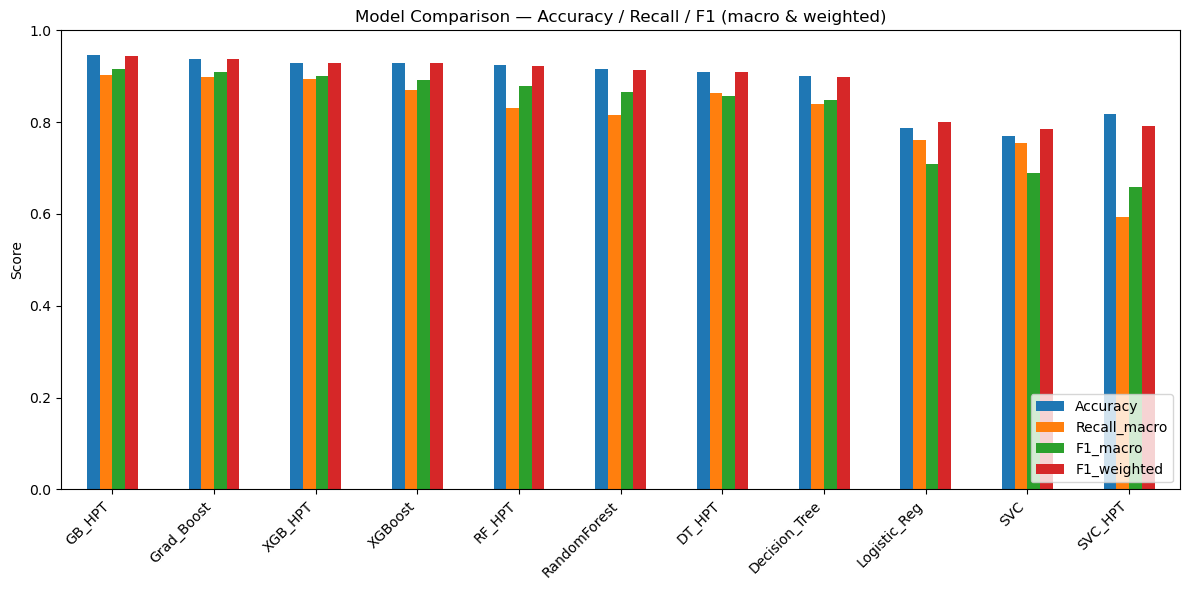

In [128]:
# Visual comparison across models

results_table[['Accuracy', 'Recall_macro', 'F1_macro', 'F1_weighted']].plot(
    kind='bar', figsize=(12,6), ylim=(0,1)
)
plt.title('Model Comparison — Accuracy / Recall / F1 (macro & weighted)')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The best model is picked **programmatically** from the actual `results` table (highest macro
F1-score — the metric that treats the "Good" and "Outstanding" minority classes as seriously as the
majority "Excellent" class) rather than hand-typed, so it always reflects whatever the notebook produced
on the last run.

In [130]:
best_model_name = results_table['F1_macro'].idxmax()
best_model = fitted_models[best_model_name]

print('Best model (by macro F1-score):', best_model_name)
results_table.loc[[best_model_name]]

Best model (by macro F1-score): GB_HPT


,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
GB_HPT,0.945833,0.930658,0.902637,0.916021,0.945162


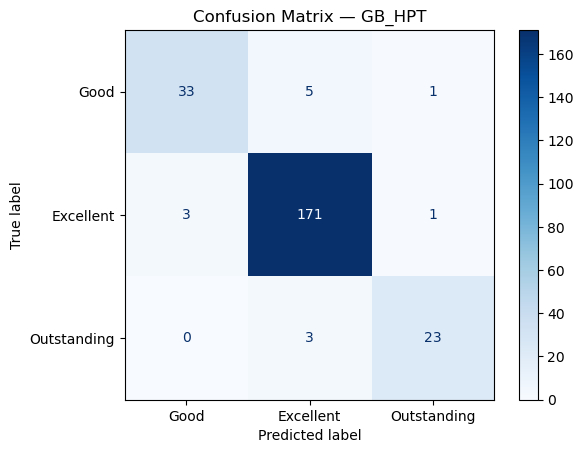

In [131]:
y_pred_best = best_model.predict(x_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=['Good', 'Excellent', 'Outstanding'], cmap='Blues'
)
plt.title(f'Confusion Matrix — {best_model_name}')
plt.show()

## Demo Prediction with the Best Model

(*As requested — this comes before the model comparison report.*)

A **random point from the held-out test set** (never seen during training or tuning) is run through
the best model identified above, as an end-to-end sanity check before writing up the comparison report.

In [134]:
random.seed()   # non-fixed seed so a different employee is picked each run; swap for random.seed(42) for a repeatable demo

demo_idx = random.choice(X_test_raw.index)
demo_employee_raw = X_test_raw.loc[[demo_idx]]
actual_label = y_test.loc[demo_idx]

print('Randomly selected test employee (original feature values):')
demo_employee_raw

Randomly selected test employee (original feature values):


,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,...,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
522,20,Female,Medical,Single,Sales,Sales Representative,Travel_Rarely,2,3,3,...,19,1,2.0,3,3,2.0,2.0,2.0,2.0,No


In [135]:
demo_employee_transformed = preprocessor.transform(demo_employee_raw)

pred = best_model.predict(demo_employee_transformed)[0]
prob = best_model.predict_proba(demo_employee_transformed)[0][pred]

print(f'Model used:        {best_model_name}')
print(f'Predicted rating:  {label_to_rating[pred]} ({label_to_name[pred]})')
print(f'Confidence:        {round(prob*100, 2)}%')
print(f'Actual rating:     {label_to_rating[actual_label]} ({label_to_name[actual_label]})')
print(f'Correct?           {pred == actual_label}')

Model used:        GB_HPT
Predicted rating:  3 (Excellent)
Confidence:        99.9%
Actual rating:     3 (Excellent)
Correct?           True


In [136]:
# Persisting the best model + preprocessor together for deployment / reuse

with open('Employee_best_model.pkl', 'wb') as f:
    pickle.dump({'model': best_model, 'model_name': best_model_name,
                 'preprocessor': preprocessor, 'label_to_rating': label_to_rating}, f)

## Task 3: Key Driver Analysis — What's Actually Driving Performance

This is the section that speaks directly to the CEO's brief: not just a model, but **evidence-based
indicators** he can act on without a blanket policy that dents morale across the whole company.

A tree-based model's `feature_importances_` are used here — if the best model above isn't tree-based
(e.g. it turned out to be SVC or Logistic Regression), the tuned Random Forest (`RF_HPT`) is used
instead purely for this interpretability step, since permutation-free feature importances aren't
available for every model type.

In [139]:
importance_source_name = best_model_name if hasattr(best_model, 'feature_importances_') else 'RF_HPT'
importance_source = fitted_models[importance_source_name]

feature_names = preprocessor.get_feature_names_out()
importances = pd.Series(importance_source.feature_importances_, index=feature_names)
top_features = importances.sort_values(ascending=False).head(15)

print(f'Feature importances taken from: {importance_source_name}')
top_features

Feature importances taken from: GB_HPT


Do_Nothing__EmpEnvironmentSatisfaction            0.324100
SS__EmpLastSalaryHikePercent                      0.261257
SS__YearsSinceLastPromotion                       0.153677
Do_Nothing__EmpWorkLifeBalance                    0.082527
OHE__EmpDepartment_Development                    0.040805
SS__ExperienceYearsInCurrentRole                  0.036444
SS__TrainingTimesLastYear                         0.009184
SS__EmpHourlyRate                                 0.008677
OHE__EducationBackground_Marketing                0.006220
OHE__EducationBackground_Technical Degree         0.005655
SS__Age                                           0.005395
Do_Nothing__EmpRelationshipSatisfaction           0.004448
SS__YearsWithCurrManager                          0.004279
OHE__BusinessTravelFrequency_Travel_Frequently    0.003868
SS__DistanceFromHome                              0.003635
dtype: float64

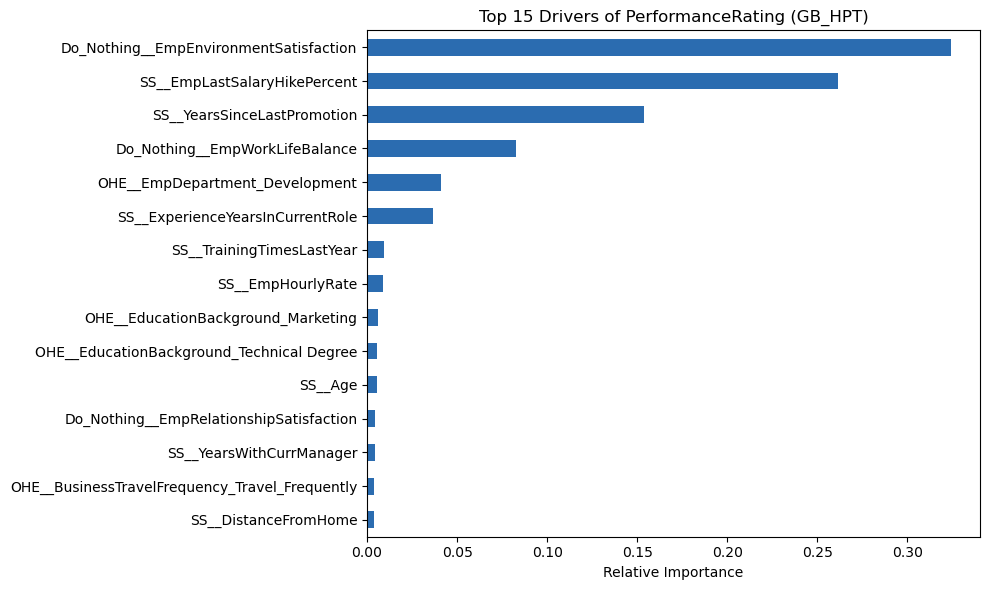

In [140]:
plt.figure(figsize=(10,6))
top_features.sort_values().plot(kind='barh', color='#2b6cb0')
plt.title(f'Top 15 Drivers of PerformanceRating ({importance_source_name})')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

#### Reading the Result for Management

- Whichever satisfaction/tenure features rank highest above are the ones worth investigating and acting
  on directly (e.g. environment satisfaction, time-since-promotion, salary hike history) — these are
  levers management can actually pull, unlike demographic features which should **not** be used as a
  basis for any personnel action even if they show up with non-trivial importance.
- **On `EmpLastSalaryHikePercent`:** flagged in the EDA as a possible feedback loop (raises may reflect
  *past* performance rather than cause *future* performance) — if it ranks highly here, treat it as a
  confirmation signal for who's already excelling, not as a lever to pull on someone rated "Good", and
  validate any action against the other, more causally-clear drivers first.
- **Recommended use, per the brief:** treat the model's output as a **screening signal**, not a final
  verdict — pair a "Good"-rated / low-confidence prediction with a manager conversation about the
  specific top drivers (e.g. "environment satisfaction is low, last promotion was 4+ years ago") rather
  than an automatic penalty. This keeps any action targeted and explainable, addressing the CEO's
  concern about morale and INX's employer reputation.

## Task 4: Model Design Analysis

#### 1. Business and Data Context
- The target has 3 classes with real imbalance (~73% / 16% / 11%), so **macro-averaged** metrics are
  used throughout — plain accuracy would reward a model that just predicts "Excellent" for everyone.
- Missing a genuinely low-performing employee (false negative on class "Good") has real business cost
  (unaddressed service issues), so Recall(macro) is watched alongside F1(macro), same priority-setting
  approach as the heart disease project.

#### 2. Basis for Model Selection
- **Metric priority:** F1(macro) first (balances precision/recall across all 3 classes equally),
  Accuracy and F1(weighted) as supporting evidence of overall fit.
- **Algorithm choice:** the same baseline-vs-ensemble ladder as the earlier classification projects —
  Logistic Regression and SVC as simpler baselines; Decision Tree, Random Forest, Gradient Boosting, and
  XGBoost as ensembles better able to capture non-linear interactions between satisfaction, tenure, and
  role features.
- **Hyperparameter tuning:** GridSearchCV for the smaller search spaces (SVC, Decision Tree),
  RandomizedSearchCV for the larger ones (Random Forest, Gradient Boosting, XGBoost), all cross-validated
  (`cv=5`) and scored on `f1_macro` specifically (not accuracy) so tuning doesn't just chase the majority
  class.

#### 3. Techniques Applied
- **SMOTE (multi-class):** balanced the training set across all 3 rating classes, fit on the training
  split only.
- **StandardScaler / OneHotEncoder / pass-through (via `ColumnTransformer`):** scaling only genuinely
  continuous columns, one-hot encoding only nominal categoricals, and leaving already-ordinal 1–4/1–5
  codes untouched.
- **Stratified train/test split:** preserved the target's class ratios in both splits.
- **Target re-encoding (`2/3/4` → `0/1/2`):** required for XGBoost's multi-class objective, with the
  mapping kept so every output is reported back in the original, human-readable rating.
- **Feature importance analysis:** added specifically to meet the project's "identify core underlying
  causes" requirement — a working model alone wouldn't answer that part of the brief.

## Task 5: Model Comparison Report

#### Objective

To evaluate multiple classification models on the employee performance dataset and identify the most suitable candidate for production deployment based on Accuracy, Precision(macro), Recall(macro), F1(macro), and F1(weighted).

#### Models Evaluated

Baseline — Logistic Regression, SVC, Decision Tree, Random Forest, Gradient Boosting, XGBoost

After Hyperparameter Tuning (HPT) — SVC_HPT, DT_HPT, RF_HPT, GB_HPT, XGB_HPT

#### Best Performance & Observations

These numbers are read directly off `results_table` rather than hand-typed, so this section always
reflects whatever the notebook actually produced on the last run.

In [148]:
print('Best Accuracy:         ', results_table['Accuracy'].idxmax(), '-', round(results_table['Accuracy'].max(), 3))
print('Best Recall (macro):   ', results_table['Recall_macro'].idxmax(), '-', round(results_table['Recall_macro'].max(), 3))
print('Best F1 (macro):       ', results_table['F1_macro'].idxmax(), '-', round(results_table['F1_macro'].max(), 3))
print('Best F1 (weighted):    ', results_table['F1_weighted'].idxmax(), '-', round(results_table['F1_weighted'].max(), 3))
print()
print('==> Overall model selected for deployment:', best_model_name)

Best Accuracy:          GB_HPT - 0.946
Best Recall (macro):    GB_HPT - 0.903
Best F1 (macro):        GB_HPT - 0.916
Best F1 (weighted):     GB_HPT - 0.945

==> Overall model selected for deployment: GB_HPT


#### Conclusion

The model identified above as `best_model_name` (selected on F1(macro), so it isn't just rewarded for
guessing "Excellent" on the majority of employees) is recommended for deployment, paired with the Key
Driver Analysis above so any action taken on its predictions is explainable to both management and
employees. As with the earlier projects, hyperparameter tuning did not uniformly improve every model —
a reminder that, on a dataset this size (1200 rows across 3 imbalanced classes), solid preprocessing and
SMOTE often matter more than exhaustive tuning.

## Task 6: Challenges Encountered Report

- **Legacy file format:** the source file was a `.xls` (not `.xlsx`), which needed converting before
  it could be read without extra package installs — a one-time fix captured at the top of this notebook.
- **3-class, imbalanced target:** unlike the earlier binary classification projects, both the modelling
  (multi-class objectives for SVC/XGBoost, target re-encoding to `0/1/2`) and the metrics (macro- vs.
  weighted-averaging) needed adapting so the smaller "Good" and "Outstanding" classes weren't drowned
  out by "Excellent".
- **Distinguishing cause from feedback loop:** `EmpLastSalaryHikePercent` is strongly associated with
  top performance, but likely **reflects** past performance as much as it **predicts** future
  performance — a reminder that feature importance identifies association, not necessarily causation,
  and needs a business-sense sanity check before being acted on.
- **The business ask went beyond "build a model":** the CEO specifically wanted explainable, targeted
  indicators rather than a black-box score, which is why a dedicated Key Driver Analysis section was
  added — a plain accuracy/F1 table alone wouldn't have satisfied the brief.
- **Hyperparameter sensitivity:** as in the earlier projects, tuned models did not always outperform
  their defaults, especially for the ensembles on a dataset this size.

#### Techniques Used

- **SMOTE (multi-class):** balanced the training set across all 3 performance-rating classes.
- **StandardScaler / OneHotEncoder / pass-through (via `ColumnTransformer`):** each applied only to the
  feature types they're appropriate for.
- **Stratified train/test split:** preserved the target's class ratios in both splits.
- **Cross-Validation (`cv=5`), scored on `f1_macro`:** used throughout hyperparameter search so tuning
  optimizes for balanced performance across classes, not just the majority class.
- **GridSearchCV / RandomizedSearchCV:** used for hyperparameter tuning, matched to each model's search
  space size.
- **Ensemble Methods (RF, GB, XGBoost) + feature importance:** used both for predictive performance and
  to directly answer the project's "identify core underlying causes" requirement.